**Proyecto final:**

**Análisis de señales ECG y detección de arritmias Proyecto**

**Presentado por:**

Karly Tarazona, Luis Montoya

1.	De los artículos: 

- https://www.nature.com/articles/s41746-023-00966-w  
- https://www.nature.com/articles/s41598-020-59821-7
- https://www.sciencedirect.com/science/article/pii/S2405844024032316

Para cada artículo hacer un diagrama de flujo de las metodologías usadas en los artículos

Explicar en sus palabras las metodologías desarrolladas

2.	Cargar el archivo Diagnostics.xlsx y realizar un análisis estadístico general de los datos. Desde la información en la base de datos resolver las siguientes preguntas 

○ ¿Qué tipo de arritmias son más prevalentes?  

○ ¿Hay arritmias que son más prevalentes para un género específico?

○ ¿Hay arritmias que son más prevalentes para una edad? 

○ Los algoritmos de aprendizaje se basan en usar la mayor cantidad de datos posibles que sean comparables, ¿Qué rango de edades y arritmias de la base de datos entregada considera que debe usar para entrenar algoritmos de aprendizaje? 

○ ¿Hay coincidencia entre lo encontrado en literatura y lo encontrado en la base de datos? 

○ ¿Qué otros análisis propone desde la base de datos? 


In [ ]:
import pandas as pd
import glob
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import rfft, rfftfreq
from pathlib import Path


Registros: 10646


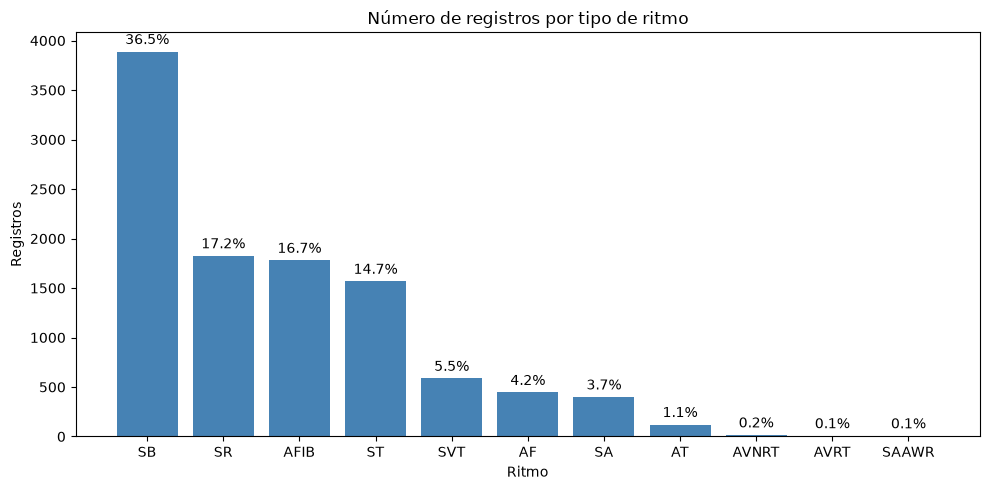

In [33]:




df = pd.read_excel("Diagnostics.xlsx")

print("Registros:", len(df))

conteo = df["Rhythm"].value_counts()

# Calcular porcentajes
porcentaje = conteo / conteo.sum() * 100

# Crear gráfico
fig, ax = plt.subplots(figsize=(10, 5))

barras = ax.bar(
    conteo.index,
    conteo.values,
    color="steelblue"
)

# Agregar porcentajes encima de las barras
ax.bar_label(
    barras,
    labels=[f"{p:.1f}%" for p in porcentaje],
    padding=3,
    fontsize=10
)

ax.set_title("Número de registros por tipo de ritmo")
ax.set_xlabel("Ritmo")
ax.set_ylabel("Registros")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


1. ¿Qué arritmias son más prevalentes?
Los ritmos más frecuentes son:

Bradicardia sinusal (SB): 36,5 %.

Ritmo sinusal (SR): 17,2 %.

Fibrilación auricular (AFIB): 16,7 %.

Taquicardia sinusal (ST): 14,7 %.


Siguen SVT (5,5 %), AF (4,2 %), SA (3,8 %) y AT (1,1 %). 

Hay tres clases casi vacías: AVNRT (16 registros), AVRT (8) y SAAWR (7).


In [34]:
genero = pd.crosstab(df["Rhythm"], df["Gender"])

porcentaje_genero = (df["Gender"].value_counts(normalize=True) * 100).round(2)

print(porcentaje_genero)

genero

Gender
MALE      55.95
FEMALE    44.05
Name: proportion, dtype: float64


Gender,FEMALE,MALE
Rhythm,,
AF,188,257
AFIB,739,1041
AT,57,64
AVNRT,12,4
AVRT,3,5
SA,176,223
SAAWR,6,1
SB,1408,2481
SR,1024,802


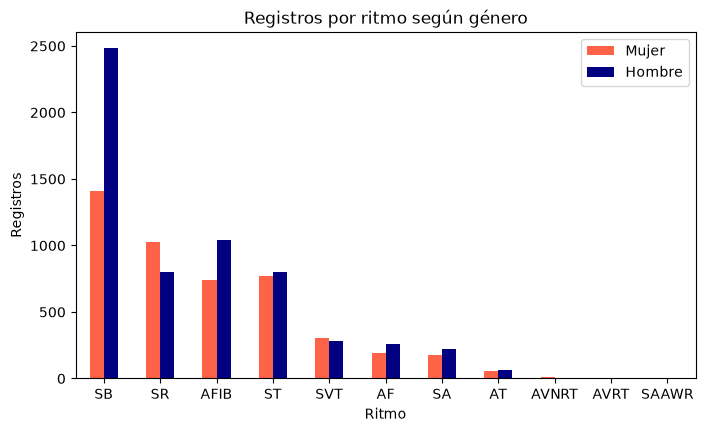

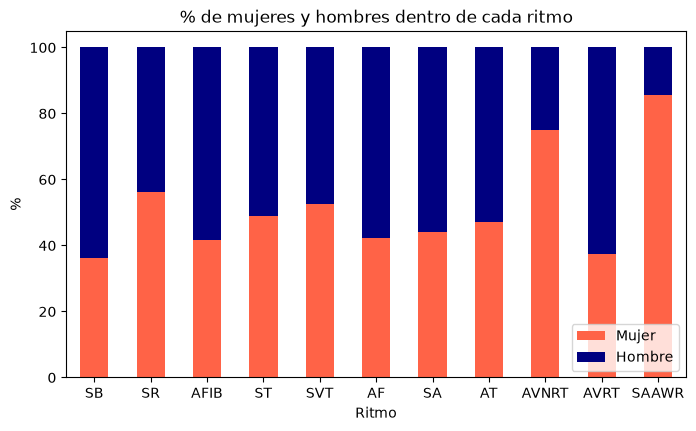

In [35]:

genero.loc[conteo.index].plot(kind="bar", color=["tomato", "navy"], figsize=(8, 4.5))
plt.title("Registros por ritmo según género")
plt.xlabel("Ritmo")
plt.ylabel("Registros")
plt.legend(["Mujer", "Hombre"])
plt.xticks(rotation=0)
plt.show()

# En porcentaje dentro de cada ritmo
porc = pd.crosstab(df["Rhythm"], df["Gender"], normalize="index") * 100
porc.loc[conteo.index].plot(kind="bar", stacked=True, color=["tomato", "navy"], figsize=(8, 4.5))
plt.title("% de mujeres y hombres dentro de cada ritmo")
plt.xlabel("Ritmo")
plt.ylabel("%")
plt.legend(["Mujer", "Hombre"], loc="lower right")
plt.xticks(rotation=0)
plt.show()

In [36]:
promedio_edad = df["PatientAge"].mean()

print(f"Promedio de edad general: {promedio_edad:.1f} años")

mediana_edad = df["PatientAge"].median()

print(f"Mediana de edad: {mediana_edad:.1f} años")

df.groupby("Rhythm")["PatientAge"].agg(["count", "mean", "median", "std", "min", "max"]).round(1).loc[conteo.index]





Promedio de edad general: 59.2 años
Mediana de edad: 62.0 años


,count,mean,median,std,min,max
Rhythm,,,,,,
SB,3889,58.3,60.0,14.0,10,98
SR,1826,54.4,55.0,16.3,4,95
AFIB,1780,73.4,75.0,11.1,30,98
ST,1568,54.6,57.0,21.1,4,96
SVT,587,55.6,56.0,18.5,4,96
AF,445,71.1,72.0,13.5,21,97
SA,399,34.7,29.0,23.0,4,93
AT,121,65.7,71.0,19.3,8,94
AVNRT,16,57.9,59.0,17.3,27,84


In [37]:

# Crear grupos de edad
df["GrupoEdad"] = pd.cut(
    df["PatientAge"],
    bins=[0, 20, 40, 60, 80, 120],
    labels=[
        "0-20",
        "21-40",
        "41-60",
        "61-80",
        "81+"
    ],
    include_lowest=True
)

# Cantidad de registros por ritmo y grupo de edad
tabla_edades = pd.crosstab(
    df["Rhythm"],
    df["GrupoEdad"]
)

print(tabla_edades)

GrupoEdad  0-20  21-40  41-60  61-80  81+
Rhythm                                   
AF            0     13     76    244  112
AFIB          0     10    218   1022  530
AT            6      8     17     67   23
AVNRT         0      3      6      4    3
AVRT          0      1      2      5    0
SA          143    110     73     65    8
SAAWR         2      1      1      1    2
SB           40    364   1639   1664  182
SR           36    335    751    613   91
ST          117    277    474    532  168
SVT          15    109    221    178   64


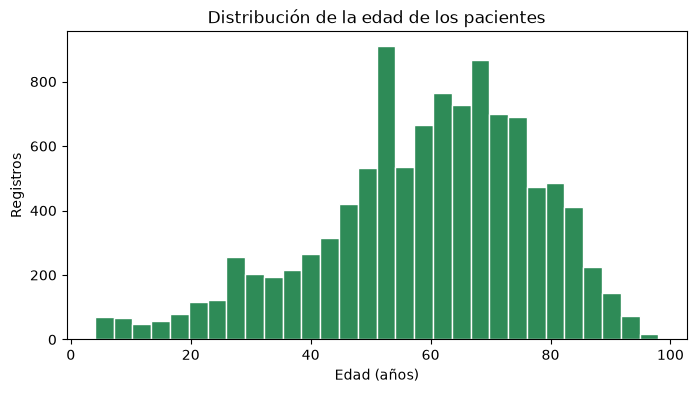

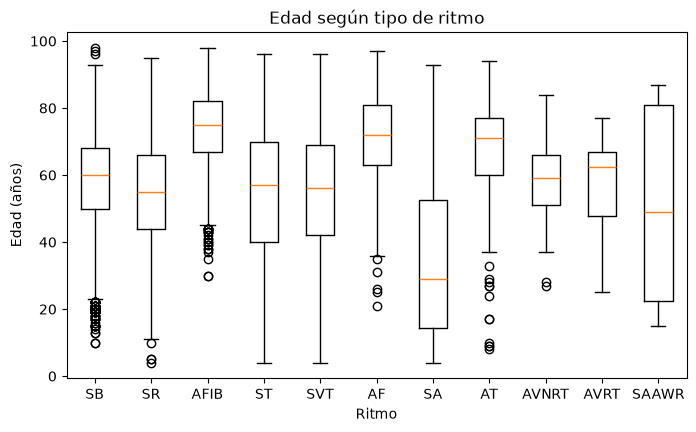

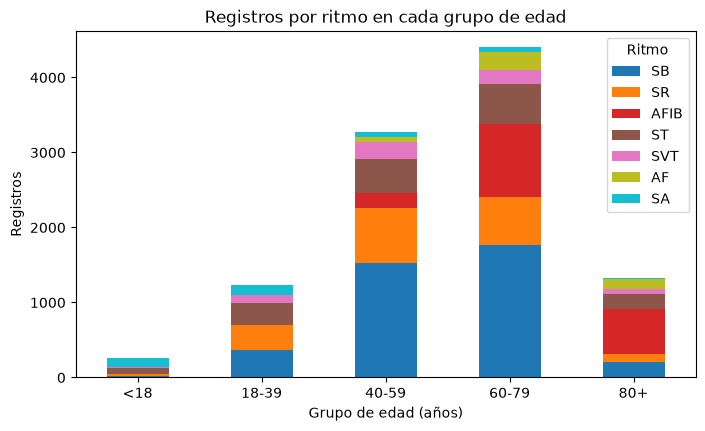

In [38]:
plt.figure(figsize=(8, 4))
plt.hist(df["PatientAge"], bins=30, color="seagreen", edgecolor="white")
plt.title("Distribución de la edad de los pacientes")
plt.xlabel("Edad (años)")
plt.ylabel("Registros")
plt.show()


# Edad por ritmo
datos = [df.loc[df["Rhythm"] == r, "PatientAge"] for r in conteo.index]
plt.figure(figsize=(8, 4.5))
plt.boxplot(datos, tick_labels=conteo.index)
plt.title("Edad según tipo de ritmo")
plt.xlabel("Ritmo")
plt.ylabel("Edad (años)")
plt.show()

# Ritmos por grupo de edad
df["GrupoEdad"] = pd.cut(df["PatientAge"], bins=[0, 17, 39, 59, 79, 120],
                         labels=["<18", "18-39", "40-59", "60-79", "80+"])
pd.crosstab(df["GrupoEdad"], df["Rhythm"])[conteo.index[:7]].plot(kind="bar", stacked=True, colormap="tab10", figsize=(8, 4.5))
plt.title("Registros por ritmo en cada grupo de edad")
plt.xlabel("Grupo de edad (años)")
plt.ylabel("Registros")
plt.legend(title="Ritmo", bbox_to_anchor=(1, 1))
plt.xticks(rotation=0)
plt.show()

AFIB: edad media 73 años. Casi todos los casos están por encima de los 60.
AF (aleteo): edad media 71 años.
SA (arritmia sinusal): mediana de 29 años, claramente la más joven. Esto es esperable, porque en jóvenes suele ser fisiológica.
SB, SR, ST y SVT: medias de 54 a 58 años.

3. Programar las fórmulas 1 al 4 que se encuentran en el artículo (15%).
Consultar que significado y utilidad del biespectro (5%)
https://arxiv.org/pdf/1809.08451

Deviation:

In [39]:
def calculate_deviation(x_0, x_n):
    """
    Calcula la desviación (Error Cuadrático Medio) entre dos arreglos.
    """
    x_0 = np.array(x_0)
    x_n = np.array(x_n)
    
    # Asegurarse de que ambos arreglos tengan la misma longitud 'k'
    k = len(x_0)
    if k != len(x_n):
        raise ValueError("Los arreglos deben tener la misma longitud.")
        
    deviation = (1 / k) * np.sum((x_0 - x_n) ** 2)
    return deviation

Compression:

In [40]:
def calculate_compression(c_tk, x_min, x_max):
    """
    Calcula la compresión (normalización min-max) para un valor o arreglo.
    """
    # Evitar la división por cero si todos los valores son iguales
    if x_max == x_min:
        raise ValueError("x_max y x_min no pueden ser iguales (división por cero).")
        
    c_tk = np.array(c_tk)
    s_tk = (c_tk - x_min) / (x_max - x_min)
    return s_tk

Bispectrum:

In [41]:
def calculate_bispectrum(X_f1, X_f2, X_f1_plus_f2):
    """
    Calcula el Biespectro dadas las transformadas X en f1, f2 y f1+f2 para N realizaciones.
    X_f1, X_f2, X_f1_plus_f2 deben ser arreglos de longitud N (para j=1 hasta N).
    """
    X_f1 = np.array(X_f1)
    X_f2 = np.array(X_f2)
    X_f1_plus_f2 = np.array(X_f1_plus_f2)
    
    # X_j^*(f1 + f2) es el conjugado complejo
    X_f1_plus_f2_conj = np.conj(X_f1_plus_f2)
    
    # Multiplicar elemento a elemento y luego sumar sobre todo j (hasta N)
    bispectrum = np.sum(X_f1 * X_f2 * X_f1_plus_f2_conj)
    return bispectrum

Bicoherence:

In [42]:
def calculate_bicoherence(X_f1, X_f2, X_f1_plus_f2):
    """
    Calcula la Bicoherencia. Los argumentos son arreglos de longitud N.
    """
    X_f1 = np.array(X_f1)
    X_f2 = np.array(X_f2)
    X_f1_plus_f2 = np.array(X_f1_plus_f2)
    
    # Calcular el término base a iterar: X_j(f1) * X_j(f2) * X_j^*(f1+f2)
    term_j = X_f1 * X_f2 * np.conj(X_f1_plus_f2)
    
    # Numerador: Valor absoluto de la suma total
    numerator = np.abs(np.sum(term_j))
    
    # Denominador: Suma de los valores absolutos individuales
    denominator = np.sum(np.abs(term_j))
    
    if denominator == 0:
        return 0.0 # Para evitar divisiones por cero
        
    bicoherence = numerator / denominator
    return bicoherence

El biespectro es una herramienta en el análisis de señales que permite analizar las relaciones entre los componentes de frecuencia de una señal. Especialmente nos permite analizar las relaciones entre la fase de diferentes componentes de frecuencia y si esas relaciones vienen de interacciones no lineales [1].  

El espectro de potencia muestra en una señal cómo se distribuye la potencia en sus frecuencias y a diferencia de esto el biespectro permite conocer si hay relaciones entre los componentes de frecuencia de la señal con información de la fase y posibles interacciones no lineales. Permite revelar información adicional de las características de una señal que el espectro de potencia no puede por sí solo [1].

Cargar los archivos y almacenar la segunda derivación de cada sujeto:

In [59]:
import os
import glob
import pandas as pd
from pathlib import Path

RUTA_CARPETA = "ECGDataDenoised"
DIAGNOSTICS_PATH = "Diagnostics.xlsx"

# 1. Verificación de los CSV
archivos_csv = glob.glob(os.path.join(RUTA_CARPETA, '*.csv'))
print(f"Archivos CSV encontrados: {len(archivos_csv)}")

if len(archivos_csv) > 0:
    ejemplo_csv = archivos_csv[0]
    stem_ejemplo = Path(ejemplo_csv).stem
    print(f"Ejemplo de ruta CSV: {ejemplo_csv}")
    print(f"Nombre extraído para buscar (stem): '{stem_ejemplo}'")

# 2. Verificación del Excel
try:
    diagnostics = pd.read_excel(DIAGNOSTICS_PATH)
    print(f"\nExcel cargado correctamente. Filas: {len(diagnostics)}")
    print("Primeros 5 nombres registrados en la columna 'FileName':")
    print(diagnostics['FileName'].head().tolist())
    
    # Comprobar si el stem del CSV de ejemplo está en el Excel
    if len(archivos_csv) > 0:
        match = stem_ejemplo in diagnostics['FileName'].values
        print(f"\n¿El nombre '{stem_ejemplo}' hace match exacto en el Excel?: {match}")
        
except Exception as e:
    print(f"\nError al intentar cargar el Excel: {e}")

Archivos CSV encontrados: 10646
Ejemplo de ruta CSV: ECGDataDenoised\MUSE_20180111_155115_19000.csv
Nombre extraído para buscar (stem): 'MUSE_20180111_155115_19000'

Excel cargado correctamente. Filas: 10646
Primeros 5 nombres registrados en la columna 'FileName':
['MUSE_20180113_171327_27000', 'MUSE_20180112_073319_29000', 'MUSE_20180111_165520_97000', 'MUSE_20180113_121940_44000', 'MUSE_20180112_122850_57000']

¿El nombre 'MUSE_20180111_155115_19000' hace match exacto en el Excel?: True


In [60]:
# Configuración de rutas y parámetros
RUTA_CARPETA = r"ECGDataDenoised"
DIAGNOSTICS_PATH = r"Diagnostics.xlsx"
FS = 500  # Frecuencia de muestreo (Hz)
DERIVACIONES = [
    'I', 'II', 'III', 'aVR', 'aVL', 'aVF', 
    'V1', 'V2', 'V3', 'V4', 'V5', 'V6'
]

# 1. Cargar el Excel e indexar por 'FileName'
diagnostics = pd.read_excel(DIAGNOSTICS_PATH).set_index('FileName')

# 2. Buscar archivos CSV
archivos_csv = glob.glob(os.path.join(RUTA_CARPETA, '*.csv'))
print(f'Procesando {len(archivos_csv)} archivos CSV...')

registros_exploracion = []

for archivo in archivos_csv:
    filename_stem = Path(archivo).stem

    # Búsqueda en el índice del Excel
    if filename_stem in diagnostics.index:
        arritmia = diagnostics.loc[filename_stem, 'Rhythm']

        if isinstance(arritmia, pd.Series):
            arritmia = arritmia.iloc[0]

        # Leer CSV indicando header=None
        df = pd.read_csv(archivo, header=None)
        
        # Asignar los nombres de los canales a las columnas
        df.columns = DERIVACIONES
        
        # Extraer ÚNICAMENTE la Derivación II y asignarla a Signal_II
        Signal_II = df['II'].values
        
        num_muestras = len(Signal_II)
        duracion_seg = num_muestras / FS

        registros_exploracion.append({
            'Archivo': filename_stem,
            'Arritmia': arritmia,
            'Muestras': num_muestras,
            'Duracion_s': duracion_seg,
            'Canal_Analizado': 'II',
            'Signal_II': Signal_II  # Ahora guardado con la 'S' mayúscula
        })

# Crear DataFrame consolidado
df_exploracion = pd.DataFrame(registros_exploracion)

Procesando 10646 archivos CSV...


In [61]:
# 1. Veamos qué columnas tiene realmente tu tabla en este momento
print("Columnas actuales:", df_exploracion.columns.tolist())

# 2. Veamos cuántas filas (señales) logró cargar
print("Cantidad de señales cargadas:", len(df_exploracion))

Columnas actuales: ['Archivo', 'Arritmia', 'Muestras', 'Duracion_s', 'Canal_Analizado', 'Signal_II']
Cantidad de señales cargadas: 10646


4. Para cada señal extraer la frecuencia que contiene la máxima potencia
(15%).

In [62]:
def obtener_frecuencia_maxima_potencia(senal, fs):
    """
    Calcula el espectro de potencia de la señal y extrae la frecuencia 
    (distinta de 0 Hz) que contiene la mayor energía.
    """
    N = len(senal)
    
    # Calcular la FFT para señales reales
    transformada = rfft(senal)
    
    # Calcular la potencia (magnitud al cuadrado)
    potencia = np.abs(transformada) ** 2
    
    # Obtener el vector de frecuencias
    frecuencias = rfftfreq(N, 1/fs)
    
    # Anular la componente de continua (0 Hz) para no sesgar el resultado
    potencia[0] = 0
    
    # Encontrar el índice donde la potencia es máxima
    indice_max = np.argmax(potencia)
    
    # Extraer la frecuencia correspondiente a ese índice
    frecuencia_maxima = frecuencias[indice_max]
    
    return frecuencia_maxima

In [63]:
# Asegúrate de tener la frecuencia de muestreo definida
FS = 500 

# Aplicar la función usando el nombre exacto de la columna con 'S' mayúscula
df_exploracion['fMP'] = df_exploracion['Signal_II'].apply(
    lambda senal: obtener_frecuencia_maxima_potencia(senal, FS)
)

# Verificar los resultados
print(df_exploracion[['Archivo', 'Arritmia', 'fMP']].head())

                      Archivo Arritmia  fMP
0  MUSE_20180111_155115_19000       ST  2.1
1  MUSE_20180111_155154_74000     AFIB  9.7
2  MUSE_20180111_155203_15000     AFIB  2.7
3  MUSE_20180111_155249_70000       ST  3.9
4  MUSE_20180111_155542_84000       AF  3.4


5. Para cada señal sumar el número de frecuencias que son significativas
para bicoherencia (cuales tienen un valor superior a √(9.2/2⋅𝑁)
(10 %).


In [64]:
def calcular_sFSB(senal, N=10):
    """
    Calcula el sFSB (Suma de Frecuencias Significativas de Bicoherencia).
    N: Número de segmentos o épocas en los que se divide la señal.
    """
    # 1. Truncar y dividir la señal en N segmentos del mismo tamaño
    L = len(senal) // N
    if L == 0:
        return 0
        
    segmentos = senal[:N*L].reshape(N, L)
    
    # 2. Transformada de Fourier para cada segmento
    X = np.fft.rfft(segmentos, axis=1)
    num_bins = X.shape[1]
    
    # 3. Crear los pares de frecuencias (f1, f2)
    # Por simetría del biespectro, solo iteramos donde f1 >= f2 y f1 + f2 < num_bins
    f1_idx, f2_idx = np.tril_indices(num_bins)
    mask = (f1_idx + f2_idx) < num_bins
    f1 = f1_idx[mask]
    f2 = f2_idx[mask]
    f3 = f1 + f2
    
    # 4. Extraer los vectores de frecuencia para todos los segmentos simultáneamente
    X1 = X[:, f1]
    X2 = X[:, f2]
    X3 = X[:, f3]
    
    # 5. Calcular Bicoherencia (fórmula de Kim & Powers)
    X12 = X1 * X2
    numerador = np.abs(np.mean(X12 * np.conj(X3), axis=0))
    denominador = np.sqrt(np.mean(np.abs(X12)**2, axis=0) * np.mean(np.abs(X3)**2, axis=0))
    
    # Evitar la división por cero en frecuencias vacías
    valid = denominador > 1e-10
    bicoherencia = np.zeros_like(numerador)
    bicoherencia[valid] = numerador[valid] / denominador[valid]
    
    # 6. Aplicar el umbral y contar (la fórmula del 10% de significancia)
    umbral = np.sqrt(9.2 / (2 * N))
    sFSB = np.sum(bicoherencia > umbral)
    
    return sFSB

In [65]:
# Aplicar la función a la columna Signal_II
print("Calculando sFSB para todas las señales... (Esto puede tomar un par de minutos)")

df_exploracion['sFSB'] = df_exploracion['Signal_II'].apply(
    lambda senal: calcular_sFSB(senal, N=10)
)

print("¡Cálculo finalizado exitosamente!")

# Verificar que fMP y sFSB estén correctamente integrados en la tabla
columnas_finales = ['Archivo', 'Arritmia', 'fMP', 'sFSB']
print("\nVista previa de las variables calculadas:")
print(df_exploracion[columnas_finales].head())

Calculando sFSB para todas las señales... (Esto puede tomar un par de minutos)
¡Cálculo finalizado exitosamente!

Vista previa de las variables calculadas:
                      Archivo Arritmia  fMP   sFSB
0  MUSE_20180111_155115_19000       ST  2.1  14909
1  MUSE_20180111_155154_74000     AFIB  9.7   1424
2  MUSE_20180111_155203_15000     AFIB  2.7   2026
3  MUSE_20180111_155249_70000       ST  3.9  10840
4  MUSE_20180111_155542_84000       AF  3.4   1142


6. Crear una rutina que aplique sobre todos los archivos de la base de
datos las rutina 3 al 5 y almacene los resultados en un dataframe
donde se pueda registro, tipo de patología y el frecuencia de máxima
potencia (fMP) y suma de frecuencias significativas en bicoherencia
(sFSB) (10 %) 

In [66]:
print("Calculando fMP y sFSB... (esto tomará un par de minutos)")

# 1. Aplicar las funciones a la señal guardada
df_exploracion['fMP'] = df_exploracion['Signal_II'].apply(
    lambda senal: obtener_frecuencia_maxima_potencia(senal, FS)
)

df_exploracion['sFSB'] = df_exploracion['Signal_II'].apply(
    lambda senal: calcular_sFSB(senal) 
)

# 2. Extraer solo las columnas de interés para el nuevo DataFrame
df_resultados = df_exploracion[['Archivo', 'Arritmia', 'fMP', 'sFSB']].copy()

# 3. Renombrar las columnas para cumplir con el formato exacto del punto 6
df_resultados.rename(columns={
    'Archivo': 'Registro',
    'Arritmia': 'Tipo_Patologia'
}, inplace=True)

print("\n¡DataFrame final creado exitosamente!")
print(df_resultados.head())

Calculando fMP y sFSB... (esto tomará un par de minutos)

¡DataFrame final creado exitosamente!
                     Registro Tipo_Patologia  fMP   sFSB
0  MUSE_20180111_155115_19000             ST  2.1  14909
1  MUSE_20180111_155154_74000           AFIB  9.7   1424
2  MUSE_20180111_155203_15000           AFIB  2.7   2026
3  MUSE_20180111_155249_70000             ST  3.9  10840
4  MUSE_20180111_155542_84000             AF  3.4   1142
